# EDA extendido - Datos de futbol de Transfermarkt (players.csv)

**Fuente:** Kaggle - *Football Data from Transfermarkt* (mexwell), encontrado en Google Dataset Search.

**Objetivo:** explorar los jugadores activos en la temporada 2022, comparar posiciones y aplicar visualizaciones nuevas: diagrama de cajas y bigotes, violin, histograma con KDE, mapa de calor y dispersion.

> Coloca `players.csv` en la misma carpeta que este notebook.

## 1. Librerias y carga de datos

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

data = pd.read_csv("players.csv", parse_dates=["date_of_birth"])
data.head()

,player_id,first_name,last_name,name,last_season,current_club_id,player_code,country_of_birth,city_of_birth,country_of_citizenship,...,foot,height_in_cm,market_value_in_eur,highest_market_value_in_eur,contract_expiration_date,agent_name,image_url,url,current_club_domestic_competition_id,current_club_name
0,597,Aleksandr,Hleb,Aleksandr Hleb,2016,2696,aleksandr-hleb,UdSSR,Minsk,Belarus,...,NaN,NaN,NaN,19000000.0,NaN,fair-sport GmbH,https://img.a.transfermarkt.technology/portrai...,https://www.transfermarkt.co.uk/aleksandr-hleb...,RU1,Krylya Sovetov Samara
1,1428,Mike,Hanke,Mike Hanke,2013,60,mike-hanke,Germany,Hamm,Germany,...,right,185.0,NaN,5000000.0,NaN,NaN,https://img.a.transfermarkt.technology/portrai...,https://www.transfermarkt.co.uk/mike-hanke/pro...,L1,SC Freiburg
2,1560,Youssef,El Akchaoui,Youssef El Akchaoui,2012,306,youssef-el-akchaoui,Netherlands,Dordrecht,Morocco,...,NaN,NaN,NaN,1750000.0,NaN,NaN,https://img.a.transfermarkt.technology/portrai...,https://www.transfermarkt.co.uk/youssef-el-akc...,NL1,SC Heerenveen
3,1587,Mario,Eggimann,Mario Eggimann,2012,42,mario-eggimann,Switzerland,Brugg,Switzerland,...,right,190.0,NaN,3000000.0,NaN,NaN,https://img.a.transfermarkt.technology/portrai...,https://www.transfermarkt.co.uk/mario-eggimann...,L1,NaN
4,1726,Heiko,Westermann,Heiko Westermann,2016,610,heiko-westermann,Germany,Alzenau,Germany,...,right,190.0,NaN,9000000.0,NaN,NaN,https://img.a.transfermarkt.technology/portrai...,https://www.transfermarkt.co.uk/heiko-westerma...,NL1,Ajax Amsterdam


## 2. Estructura y calidad de los datos

In [15]:
# Tamano, tipos de datos y valores no nulos
print(data.shape)
data.info()

(28459, 23)
<class 'pandas.DataFrame'>
RangeIndex: 28459 entries, 0 to 28458
Data columns (total 23 columns):
 #   Column                                Non-Null Count  Dtype         
---  ------                                --------------  -----         
 0   player_id                             28459 non-null  int64         
 1   first_name                            26609 non-null  str           
 2   last_name                             28459 non-null  str           
 3   name                                  28459 non-null  str           
 4   last_season                           28459 non-null  int64         
 5   current_club_id                       28459 non-null  int64         
 6   player_code                           28459 non-null  str           
 7   country_of_birth                      26660 non-null  str           
 8   city_of_birth                         26670 non-null  str           
 9   country_of_citizenship                28458 non-null  str           
 1

In [16]:
# Valores faltantes y duplicados
print("Valores nulos por columna:")
print(data.isnull().sum()[data.isnull().sum() > 0])
print(f"\nRegistros duplicados: {data.duplicated().sum()}")

Valores nulos por columna:
first_name                      1850
country_of_birth                1799
city_of_birth                   1789
country_of_citizenship             1
date_of_birth                     42
sub_position                     159
foot                            2074
height_in_cm                    1718
market_value_in_eur            10521
highest_market_value_in_eur     1022
contract_expiration_date       10513
agent_name                     14472
current_club_name               9405
dtype: int64

Registros duplicados: 0


In [17]:
# Registros por temporada (last_season) y por posicion
print(data["last_season"].value_counts().sort_index().tail(6))
print()
print(data["position"].value_counts())

last_season
2017    1865
2018    2392
2019    1958
2020    2551
2021    3961
2022    6533
Name: count, dtype: int64

position
Defender      9097
Midfield      8228
Attack        7720
Goalkeeper    3255
Missing        159
Name: count, dtype: int64


**Observaciones**
- 28.459 jugadores y 23 columnas; no hay duplicados.
- Hay muchos nulos en `market_value_in_eur` (10.521), `agent_name` y `contract_expiration_date`: son jugadores retirados o sin valor registrado.
- `last_season` indica la ultima temporada del jugador: se trabaja solo con **activos (2022)** para que los valores sean comparables.

## 3. Preparacion de los datos

In [18]:
# Jugadores activos en la temporada 2022
df = data[data["last_season"] == 2022].copy()

# Variable nueva: edad en 2022
df["edad"] = 2022 - df["date_of_birth"].dt.year

# Quitar posicion desconocida y filas sin altura o valor de mercado
df = df[df["position"] != "Missing"]
df = df.dropna(subset=["height_in_cm", "market_value_in_eur", "edad"])

# Valor en millones de euros y en escala logaritmica
df["valor_millones"] = df["market_value_in_eur"] / 1_000_000
df["log_valor"] = np.log10(df["market_value_in_eur"])

num_cols = ["edad", "height_in_cm", "market_value_in_eur", "highest_market_value_in_eur"]
print(df.shape)

(6340, 26)


## 4. Estadistica descriptiva

In [19]:
resumen = pd.DataFrame({
    "media": df[num_cols].mean(),
    "mediana": df[num_cols].median(),
    "desv_std": df[num_cols].std(),
    "IQR": df[num_cols].quantile(0.75) - df[num_cols].quantile(0.25),
    "coef_variacion_%": df[num_cols].std() / df[num_cols].mean() * 100,
    "asimetria": df[num_cols].skew(),
    "curtosis": df[num_cols].kurt()
})
resumen.round(2)

,media,mediana,desv_std,IQR,coef_variacion_%,asimetria,curtosis
edad,25.57,25.0,4.61,7.0,18.03,0.38,-0.43
height_in_cm,182.61,183.0,6.91,10.0,3.78,-0.07,-0.42
market_value_in_eur,5353678.23,1300000.0,11316651.22,4600000.0,211.38,4.98,37.34
highest_market_value_in_eur,8906579.65,2500000.0,16317624.97,9300000.0,183.21,4.04,23.61


In [20]:
# Estadisticos por posicion
df.groupby("position")[["edad", "height_in_cm", "valor_millones"]].agg(["mean", "median", "std"]).round(2)

edad              height_in_cm              valor_millones  \
             mean median   std         mean median   std           mean   
position                                                                  
Attack      25.32   25.0  4.39       180.49  180.0  6.69           6.56   
Defender    25.65   25.0  4.41       183.70  184.0  6.31           4.85   
Goalkeeper  26.58   26.0  5.66       190.39  190.0  4.25           2.43   
Midfield    25.25   25.0  4.49       179.93  180.0  5.82           6.08   

                          
           median    std  
position                  
Attack        1.7  13.98  
Defender      1.5   9.39  
Goalkeeper    0.4   6.27  
Midfield      1.5  12.06

In [21]:
# Outliers por metodo IQR
filas = []
for c in ["edad", "height_in_cm", "market_value_in_eur"]:
    q1, q3 = df[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    lim_inf, lim_sup = q1 - 1.5*iqr, q3 + 1.5*iqr
    n = ((df[c] < lim_inf) | (df[c] > lim_sup)).sum()
    filas.append({"variable": c, "lim_inf": lim_inf, "lim_sup": lim_sup,
                  "n_outliers": n, "%": round(n/len(df)*100, 1)})
pd.DataFrame(filas)

,variable,lim_inf,lim_sup,n_outliers,%
0,edad,11.5,39.5,11,0.2
1,height_in_cm,163.0,203.0,5,0.1
2,market_value_in_eur,-6500000.0,11900000.0,818,12.9


**Observaciones**
- `market_value_in_eur` tiene asimetria muy alta (~5): la media (5.35 M) es mucho mayor que la mediana (1.3 M).
- ~13 % de los jugadores son outliers en valor de mercado (> 11.9 M): son las estrellas, no errores de datos. Se conservan.
- `height_in_cm` y `edad` tienen distribucion simetrica y pocos outliers.

## 5. Visualizaciones

### 5.1 Diagrama de cajas y bigotes (boxplot)

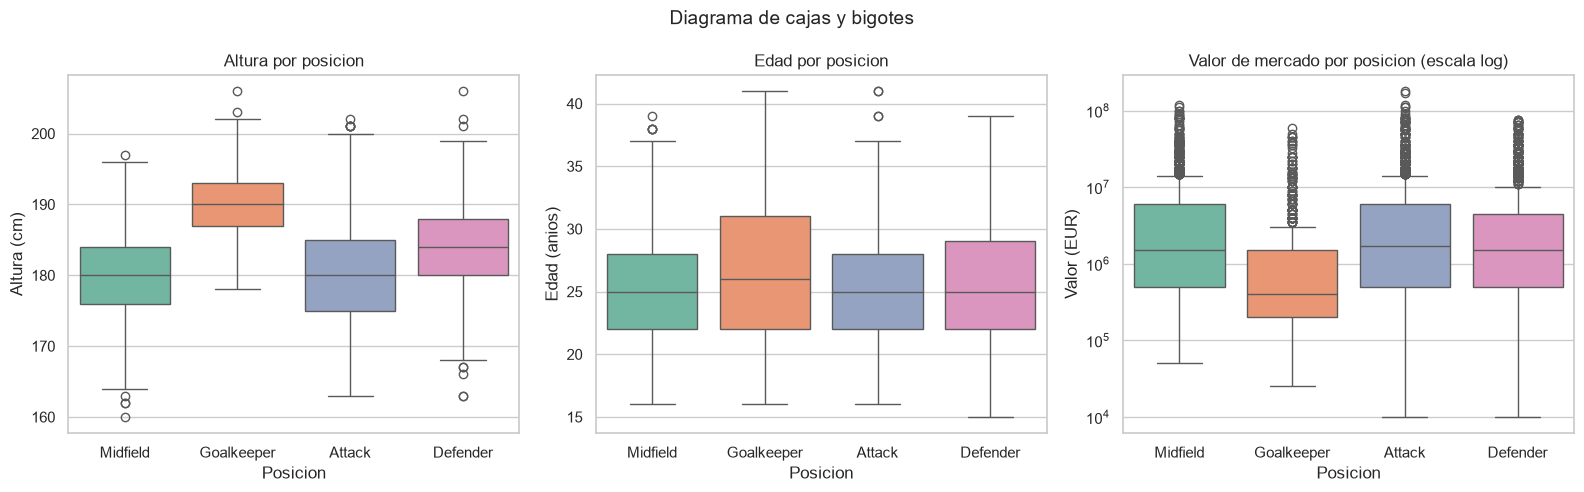

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

sns.boxplot(data=df, x="position", y="height_in_cm", hue="position", palette="Set2", ax=axes[0], legend=False)
axes[0].set_title("Altura por posicion")
axes[0].set_xlabel("Posicion")
axes[0].set_ylabel("Altura (cm)")

sns.boxplot(data=df, x="position", y="edad", hue="position", palette="Set2", ax=axes[1], legend=False)
axes[1].set_title("Edad por posicion")
axes[1].set_xlabel("Posicion")
axes[1].set_ylabel("Edad (anios)")

sns.boxplot(data=df, x="position", y="market_value_in_eur", hue="position", palette="Set2", ax=axes[2], legend=False)
axes[2].set_yscale("log")
axes[2].set_title("Valor de mercado por posicion (escala log)")
axes[2].set_xlabel("Posicion")
axes[2].set_ylabel("Valor (EUR)")

plt.suptitle("Diagrama de cajas y bigotes", fontsize=14)
plt.tight_layout()
plt.show()

**Interpretacion**
- **Altura:** los porteros son claramente mas altos (mediana ~190 cm) que delanteros y mediocampistas (~180 cm); los defensas quedan en medio (~184 cm). Los porteros tambien tienen menos dispersion.
- **Edad:** las cuatro posiciones tienen mediana cercana a 25 anios (porteros 26). Los pocos outliers de edad aparecen en delanteros y mediocampistas; defensas y porteros no tienen.
- **Valor de mercado:** se uso escala logaritmica porque los valores abarcan de miles a 180 M. Los porteros tienen la mediana mas baja (~0.4 M vs ~1.5-1.7 M del resto). Todas las posiciones tienen muchos outliers altos.

**Conclusion:** la posicion afecta la altura y el valor de mercado, pero casi no la edad.

### 5.2 Grafico de violin

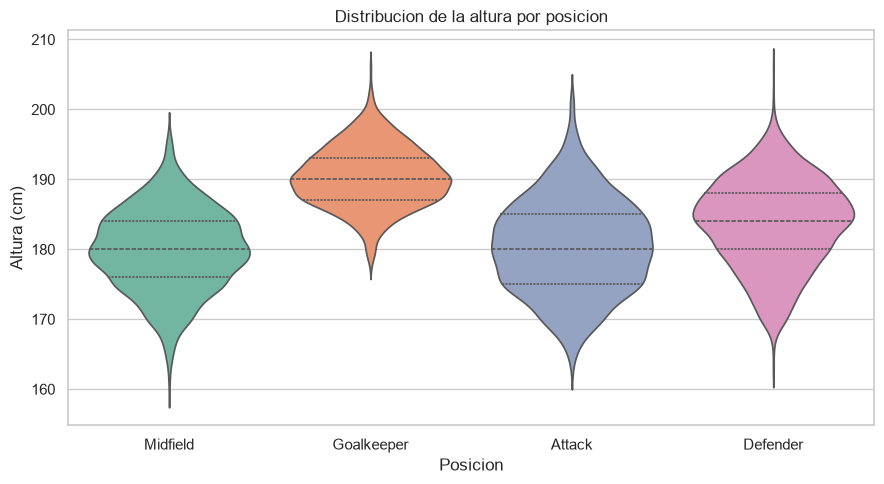

In [23]:
plt.figure(figsize=(9, 5))
sns.violinplot(data=df, x="position", y="height_in_cm", hue="position", palette="Set2",
               inner="quartile", legend=False)
plt.title("Distribucion de la altura por posicion")
plt.xlabel("Posicion")
plt.ylabel("Altura (cm)")
plt.tight_layout()
plt.show()

**Interpretacion**
- Las distribuciones son aproximadamente simetricas y de una sola cima (unimodales).
- Porteros: cima centrada en ~190 cm y forma mas angosta (desviacion ~4 cm), es decir, muy homogeneos.
- Delanteros, mediocampistas y defensas: formas mas anchas (desviacion ~6-7 cm) y mayor variedad de alturas.

**Conclusion:** el violin muestra la forma de la distribucion que el boxplot no revela; confirma que el perfil fisico del portero es el mas uniforme.

### 5.3 Histograma con KDE

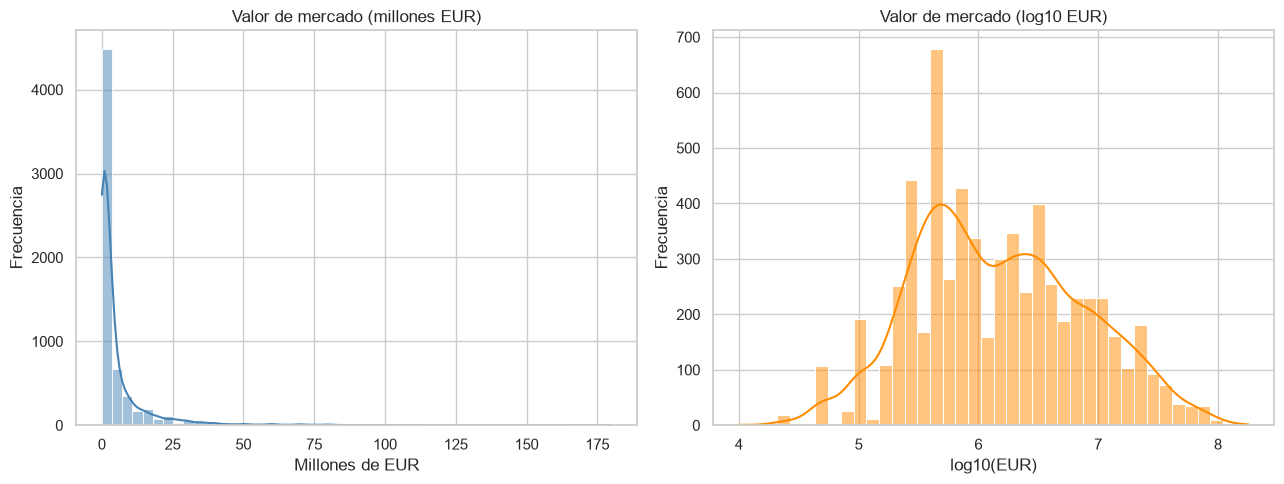

Asimetria original: 4.98
Asimetria log: 0.2


In [24]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.histplot(df["valor_millones"], bins=50, kde=True, color="steelblue", ax=axes[0])
axes[0].set_title("Valor de mercado (millones EUR)")
axes[0].set_xlabel("Millones de EUR")
axes[0].set_ylabel("Frecuencia")

sns.histplot(df["log_valor"], bins=40, kde=True, color="darkorange", ax=axes[1])
axes[1].set_title("Valor de mercado (log10 EUR)")
axes[1].set_xlabel("log10(EUR)")
axes[1].set_ylabel("Frecuencia")

plt.tight_layout()
plt.show()

print("Asimetria original:", round(df["market_value_in_eur"].skew(), 2))
print("Asimetria log:", round(df["log_valor"].skew(), 2))

**Interpretacion**
- Izquierda: la mayoria de jugadores vale menos de 5 M y hay una cola larga a la derecha (asimetria ~5).
- Derecha: con logaritmo la distribucion se vuelve casi simetrica (asimetria ~0.2).

**Conclusion:** el valor de mercado sigue una distribucion muy sesgada; para correlaciones o modelos conviene transformarlo con logaritmo.

### 5.4 Mapa de calor de correlaciones

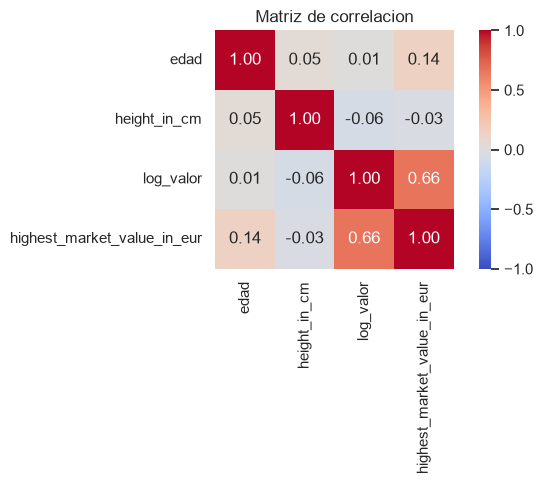

In [25]:
plt.figure(figsize=(7, 5))
sns.heatmap(df[["edad", "height_in_cm", "log_valor", "highest_market_value_in_eur"]].corr(),
            annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Matriz de correlacion")
plt.tight_layout()
plt.show()

**Interpretacion**
- `market_value_in_eur` y `highest_market_value_in_eur` tienen correlacion fuerte (0.84 sin log; 0.66 usando `log_valor`): quien vale mucho hoy suele haber tenido un maximo historico alto.
- La altura casi no se relaciona con las demas variables (~0).
- La edad tiene correlacion lineal casi nula con el valor.

**Conclusion:** la edad y la altura no explican el valor de mercado de forma lineal; la edad podria tener relacion no lineal (ver 5.5).

### 5.5 Dispersion: edad vs valor de mercado

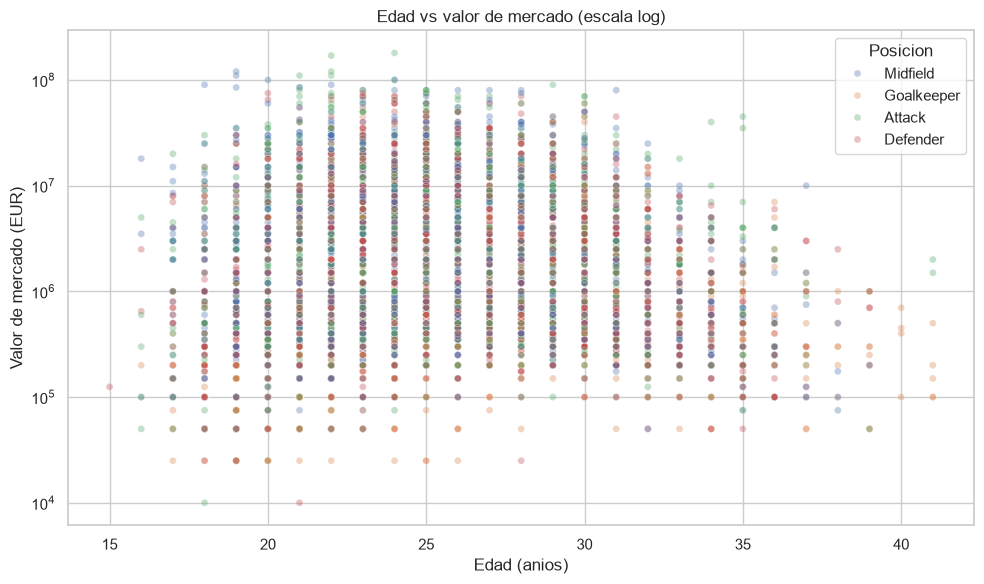

edad
(15, 20]    0.5
(20, 25]    1.5
(25, 30]    2.0
(30, 35]    0.8
(35, 45]    0.3
Name: valor_millones, dtype: float64

In [26]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x="edad", y="market_value_in_eur", hue="position", alpha=0.35, s=25)
plt.yscale("log")
plt.title("Edad vs valor de mercado (escala log)")
plt.xlabel("Edad (anios)")
plt.ylabel("Valor de mercado (EUR)")
plt.legend(title="Posicion")
plt.tight_layout()
plt.show()

# Mediana del valor por rango de edad
df.groupby(pd.cut(df["edad"], [15, 20, 25, 30, 35, 45]), observed=True)["valor_millones"].median().round(2)

**Interpretacion**
- La nube no sigue una recta, sino una curva en "U invertida": la mediana sube de 0.5 M (15-20 anios) a 1.5 M (21-25) y llega a su maximo de 2 M a los 26-30; luego baja a 0.8 M (31-35) y 0.3 M (36+).
- Por eso la correlacion lineal es casi 0 aunque la edad si influye.
- Los valores mas altos se concentran entre los 21 y 30 anios.

**Conclusion:** el valor de mercado es maximo en la edad de maximo rendimiento; Pearson no capta relaciones no lineales.

## 6. Conclusiones generales
- Se analizaron 6.340 jugadores activos en 2022 (tras limpiar nulos).
- El valor de mercado es muy asimetrico: pocos jugadores concentran valores extremos; los outliers son estrellas reales y se conservan.
- Los porteros son mas altos, mas homogeneos y valen menos que el resto.
- La edad se relaciona con el valor de forma no lineal (maximo entre 26 y 30 anios).
- La altura no explica el valor de mercado.